# Day → night darkening test (10-image sample)

Run the cells top to bottom. This only needs a CPU runtime (no GPU).

1. **Settings** – paths and pass/fail thresholds.
2. **Night simulator** – the conversion function (defines functions only, prints nothing).
3. **Load sample** – upload `sample_10.zip` made by `pick_sample_10.py` (or use a local `sample_10/` folder).
4. **Run + compare** – every image is rendered as *day | dusk | night | deep_night* with the pothole boxes drawn on. A table gives brightness, noise and a verdict per image. Figures are saved to `sample_results/`.
5. **Calibrate (optional)** – compare the synthetic looks with real night photos.
6. **Full dataset (optional, off by default)** – only after you are happy with step 4.

How to judge: look at the pictures first, the table second. The verdict flags are heuristics.


In [ ]:
import io, math, shutil, zipfile
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

# ---- Settings ----
SAMPLE_DIR = "sample_10"      # folder containing images/ and labels/
OUT_DIR = "sample_results"    # night images + comparison PNGs are saved here
SEED = 42
SHOW_LOOKS = ["dusk", "night", "deep_night"]   # which night looks to render per image
IMAGES_PER_FIGURE = 5

# Heuristic pass/fail thresholds (tune freely)
MAX_TARGET_ERR = 0.30   # output mean brightness may differ from its target by this fraction
MAX_BLACK_PCT = 50      # % of pixels below 8/255 before we call the image "crushed"
MIN_CNR_NIGHT = 0.6     # a pothole that was clearly visible by day (CNR >= 0.8) should stay above this at night

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")


In [ ]:
# ---- Night simulator (functions only) ----
W_BGR = np.array([0.114, 0.587, 0.299], np.float32)    # same weights as cv2 BGR2GRAY
GAMMA = 2.2
HEAD_TINT = np.array([0.80, 0.93, 1.00], np.float32)   # warm headlight (BGR order)
AMB_TINT = np.array([1.20, 1.00, 0.85], np.float32)    # cool, bluish ambient (BGR order)

# target_mean = average brightness of the night image (0-255, lower = darker)
# peak        = photon count scale (lower = grainier)
# read_std    = extra electronic noise in the dark
# beam        = headlight cone tightness, ambient = brightness floor outside the cone
PRESETS = {
    "dusk":       dict(target_mean=70, peak=1500, read_std=0.004, beam=1.2, ambient=0.25),
    "night":      dict(target_mean=40, peak=800,  read_std=0.006, beam=1.8, ambient=0.12),
    "deep_night": dict(target_mean=22, peak=400,  read_std=0.010, beam=2.4, ambient=0.07),
}


def mean_luma(img):
    return float(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).mean())


def noise_sigma(img):
    """Rough noise estimate (Immerkaer). Texture counts as noise, so compare like with like only."""
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
    h, w = g.shape
    return float(math.sqrt(math.pi / 2) / (6.0 * (w - 2) * (h - 2)) * np.abs(cv2.filter2D(g, -1, k)).sum())


def _exposure_for_target(lin, target):
    """Gain that makes the final (sRGB) mean brightness land on `target` (0-255)."""
    small = cv2.resize(lin, (96, 96), interpolation=cv2.INTER_AREA)
    lo, hi = -14.0, 14.0                                # search over log2(gain)
    for _ in range(32):
        mid = (lo + hi) / 2
        enc = np.clip(small * 2.0 ** mid, 0, 1) ** (1 / GAMMA)
        if 255.0 * float((enc @ W_BGR).mean()) < target:
            lo = mid
        else:
            hi = mid
    return 2.0 ** ((lo + hi) / 2)


def to_night(img, rng, target_mean=40, peak=800, read_std=0.006, beam=1.8, ambient=0.12,
             cx=0.5, cy=1.0, illum_strength=0.85, illum_sigma_frac=0.08, desat=0.3, max_ratio=0.7):
    """BGR uint8 day image -> (BGR uint8 night image, info dict).

    Works for any input brightness: the output is auto-exposed to `target_mean`,
    and is never brighter than max_ratio x its own daytime brightness.
    """
    h, w = img.shape[:2]
    before = mean_luma(img)
    target = float(min(target_mean, max_ratio * before))

    x = (img.astype(np.float32) / 255.0) ** GAMMA                       # linear light

    # 1. flatten the original lighting (sun patches, tree shadows), keep surface colour
    lum = x @ W_BGR
    illum = cv2.GaussianBlur(lum, (0, 0), sigmaX=max(h, w) * illum_sigma_frac)
    base = max(float(illum.mean()), 1e-4)
    shading = np.clip(illum / base, 0.25, 4.0) ** illum_strength
    reflect = np.clip(x / (shading[..., None] * base), 0, 4.0)

    # 2. synthetic headlight cone + dim bluish ambient light
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    d = ((xx / max(w - 1, 1) - cx) / 0.5) ** 2 + ((yy / max(h - 1, 1) - cy) / 0.9) ** 2
    cone = np.exp(-beam * d)[..., None].astype(np.float32)
    light = ambient * AMB_TINT + (1.0 - ambient) * cone * HEAD_TINT
    unit = reflect * light

    # 3. auto-exposure to the target brightness
    lit = np.clip(unit * _exposure_for_target(unit, target), 0, 1)

    # 4. sensor noise: shot (Poisson) + read (Gaussian)
    lit = rng.poisson(lit * peak).astype(np.float32) / peak
    lit = lit + rng.normal(0, read_std, lit.shape).astype(np.float32)
    enc = np.clip(lit, 0, 1) ** (1 / GAMMA)

    # 5. slight desaturation, as in real low light
    out = (enc * 255.0).astype(np.uint8)
    gray = cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)[..., None].astype(np.float32)
    out = np.clip((1 - desat) * out + desat * gray, 0, 255).astype(np.uint8)
    return out, dict(target=target, mean_before=before, mean_after=mean_luma(out))


def sample_params(rng):
    """Random night look (for the full dataset): pick a preset, then jitter it."""
    name = str(rng.choice(list(PRESETS)))
    p = dict(PRESETS[name])
    p["target_mean"] *= rng.uniform(0.8, 1.25)
    p["peak"] *= rng.uniform(0.7, 1.4)
    p["read_std"] *= rng.uniform(0.7, 1.6)
    p["beam"] *= rng.uniform(0.8, 1.3)
    p["cx"] = float(np.clip(0.5 + rng.uniform(-0.15, 0.15), 0.25, 0.75))
    p["cy"] = float(np.clip(1.0 + rng.uniform(-0.10, 0.10), 0.85, 1.15))
    return name, p


# ---- helpers: files, labels, checks ----
def read_image(path):
    data = np.fromfile(str(path), dtype=np.uint8)           # also works with odd Windows paths
    return cv2.imdecode(data, cv2.IMREAD_COLOR) if data.size else None


def write_image(path, img):
    ok, buf = cv2.imencode(Path(path).suffix.lower() or ".jpg", img)
    if ok:
        buf.tofile(str(path))
    return ok


def read_boxes(label_path, w, h):
    """YOLO label file -> pixel boxes (x0, y0, x1, y1). Handles box and polygon rows."""
    p = Path(label_path)
    boxes = []
    if not p.exists():
        return boxes
    for line in p.read_text().splitlines():
        v = line.split()
        if len(v) < 5:
            continue
        nums = [float(t) for t in v[1:]]
        if len(nums) == 4:
            cx_, cy_, bw, bh = nums
            x0, y0, x1, y1 = cx_ - bw / 2, cy_ - bh / 2, cx_ + bw / 2, cy_ + bh / 2
        else:
            xs, ys = nums[0::2], nums[1::2]
            x0, y0, x1, y1 = min(xs), min(ys), max(xs), max(ys)
        boxes.append((max(0, int(x0 * w)), max(0, int(y0 * h)), min(w, int(x1 * w)), min(h, int(y1 * h))))
    return [b for b in boxes if b[2] - b[0] > 2 and b[3] - b[1] > 2]


def box_cnr(img, boxes, pad=0.5):
    """Contrast-to-noise of each box vs a ring around it: |mean difference| / ring std.
    Falls as the pothole sinks into darkness and grain."""
    if not boxes:
        return None
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
    H, W = g.shape
    vals = []
    for x0, y0, x1, y1 in boxes:
        bw, bh = x1 - x0, y1 - y0
        X0, Y0 = max(0, int(x0 - pad * bw)), max(0, int(y0 - pad * bh))
        X1, Y1 = min(W, int(x1 + pad * bw)), min(H, int(y1 + pad * bh))
        mask = np.ones((Y1 - Y0, X1 - X0), bool)
        mask[y0 - Y0:y1 - Y0, x0 - X0:x1 - X0] = False
        ring, inner = g[Y0:Y1, X0:X1][mask], g[y0:y1, x0:x1]
        if inner.size < 16 or ring.size < 16:
            continue
        vals.append(abs(inner.mean() - ring.mean()) / (ring.std() + 1.0))
    return float(np.mean(vals)) if vals else None


def verdict(r):
    if r["day_mean"] < 5:
        return "INPUT IS BLACK"
    flags = []
    if abs(r["night_mean"] - r["target"]) > MAX_TARGET_ERR * max(r["target"], 1):
        flags.append("OFF TARGET")
    if r["night_mean"] >= r["day_mean"]:
        flags.append("NOT DARKER")
    if r["black_pct"] > MAX_BLACK_PCT:
        flags.append("CRUSHED")
    cd, cn = r["cnr_day"], r["cnr_night"]
    if cd is not None and cn is not None and cd >= 0.8 and cn < MIN_CNR_NIGHT:
        flags.append("POTHOLE FADED")
    return ", ".join(flags) or "OK"


In [ ]:
# ---- Load the sample ----
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not (Path(SAMPLE_DIR) / "images").exists():
    if not IN_COLAB:
        raise FileNotFoundError(f"Put your sample in ./{SAMPLE_DIR}/images and ./{SAMPLE_DIR}/labels")
    print("Upload sample_10.zip (or the loose image + .txt label files):")
    up = files.upload()
    (Path(SAMPLE_DIR) / "images").mkdir(parents=True, exist_ok=True)
    (Path(SAMPLE_DIR) / "labels").mkdir(parents=True, exist_ok=True)
    for name, data in up.items():
        low = name.lower()
        if low.endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(data)).extractall(".")
        elif low.endswith(IMG_EXT):
            (Path(SAMPLE_DIR) / "images" / name).write_bytes(data)
        elif low.endswith(".txt"):
            (Path(SAMPLE_DIR) / "labels" / name).write_bytes(data)

n_img = len([p for p in (Path(SAMPLE_DIR) / "images").iterdir() if p.suffix.lower() in IMG_EXT])
n_lab = len(list((Path(SAMPLE_DIR) / "labels").glob("*.txt"))) if (Path(SAMPLE_DIR) / "labels").exists() else 0
print(f"Sample ready: {n_img} images, {n_lab} label files in ./{SAMPLE_DIR}")
if n_img == 0:
    raise FileNotFoundError(f"No images found in ./{SAMPLE_DIR}/images - check the upload.")


Upload sample_10.zip (or the loose image + .txt label files):


Saving sample_10.zip to sample_10.zip
Sample ready: 10 images, 10 label files in ./sample_10


,image,look,boxes,day_mean,target,night_mean,black_pct,noise,cnr_day,cnr_night,verdict
0,img-127_jpg.rf.2d83b60acc45a,dusk,3,145.49,70.00,68.72,0.02,2.99,0.71,0.33,OK
1,img-127_jpg.rf.2d83b60acc45a,night,3,145.49,40.00,37.42,1.19,6.57,0.71,0.20,OK
2,img-127_jpg.rf.2d83b60acc45a,deep_night,3,145.49,22.00,19.90,17.96,10.90,0.71,0.08,OK
3,img-564_jpg.rf.628164450d017,dusk,5,133.19,70.00,67.90,0.93,3.47,0.84,0.81,OK
4,img-564_jpg.rf.628164450d017,night,5,133.19,40.00,37.50,4.28,6.50,0.84,0.67,OK
5,img-564_jpg.rf.628164450d017,deep_night,5,133.19,22.00,20.31,17.88,10.86,0.84,0.28,POTHOLE FADED
6,img-573_jpg.rf.5fe040e1ffcb2,dusk,1,191.39,70.00,68.36,0.13,3.07,1.52,0.35,POTHOLE FADED
7,img-573_jpg.rf.5fe040e1ffcb2,night,1,191.39,40.00,37.21,1.60,6.65,1.52,0.03,POTHOLE FADED
8,img-573_jpg.rf.5fe040e1ffcb2,deep_night,1,191.39,22.00,19.96,18.29,10.82,1.52,0.05,POTHOLE FADED
9,img-628_jpg.rf.6cde40eb03247,dusk,1,118.59,70.00,65.67,1.40,5.91,0.99,0.35,POTHOLE FADED



Average per look:


,day_mean,night_mean,black_pct,noise
look,,,,
deep_night,130.7,20.4,18.7,10.8
dusk,130.7,65.1,2.4,4.3
night,130.7,37.4,4.6,6.9



Verdicts: {'OK': 21, 'POTHOLE FADED': 9}


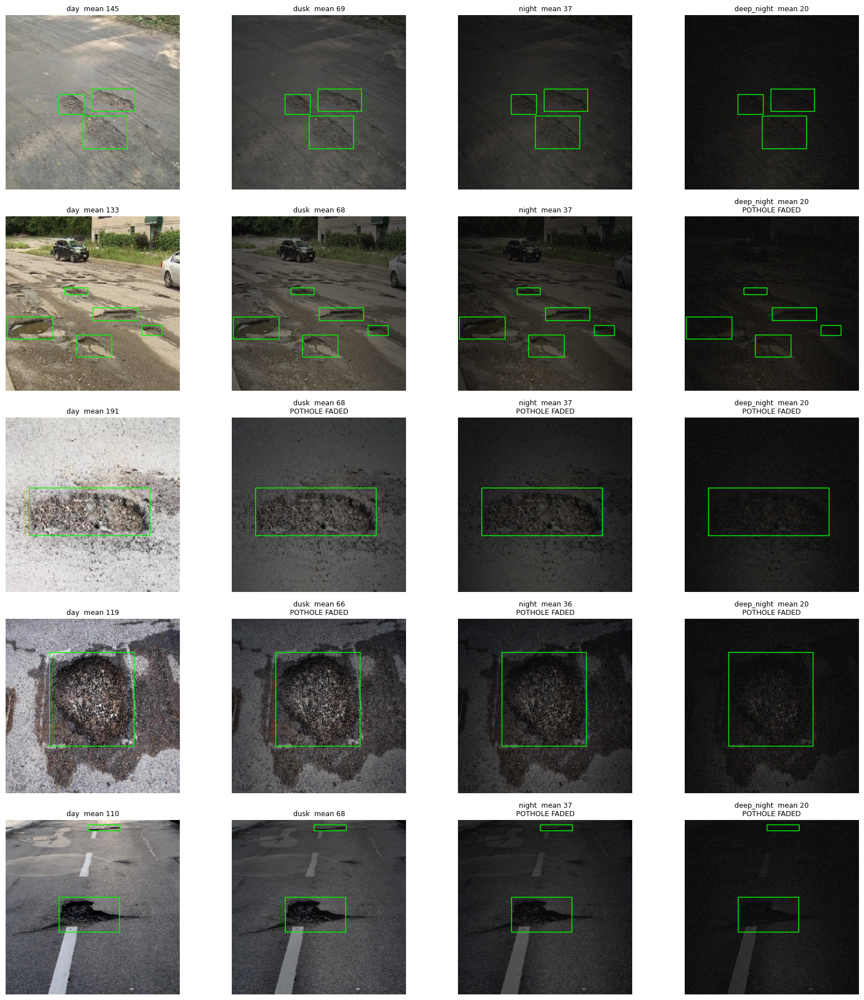

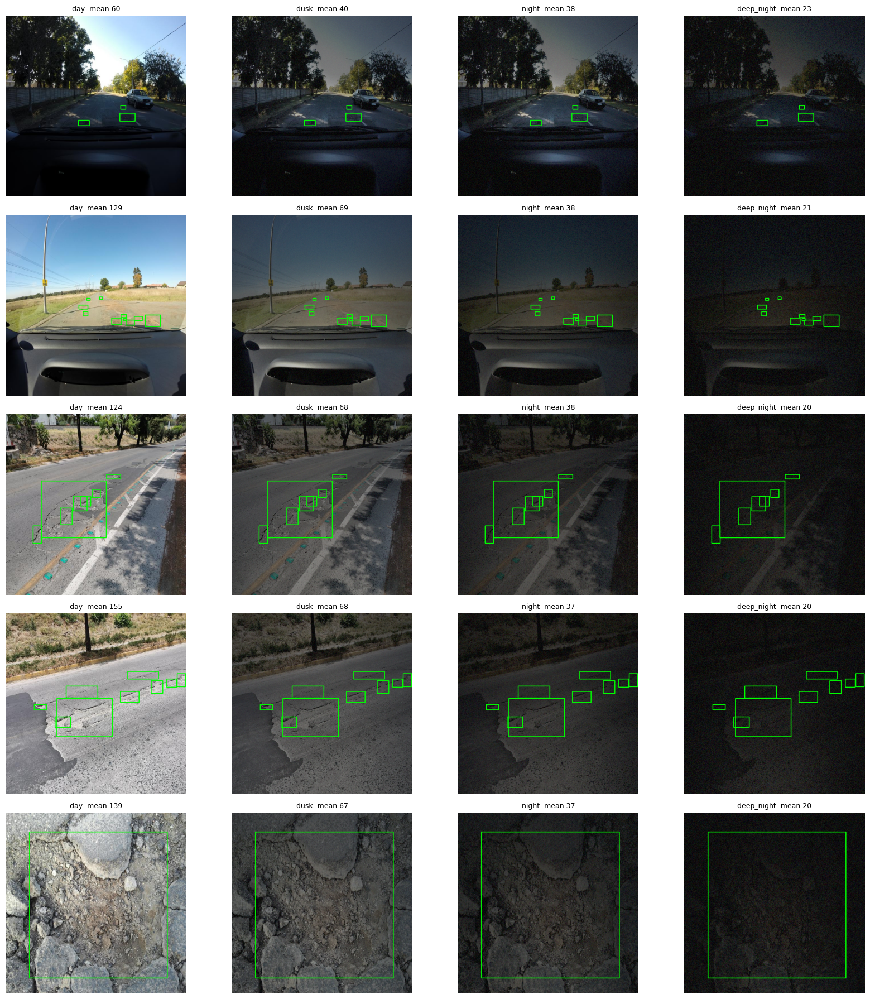

Saved night images and comparison PNGs in ./sample_results/


In [ ]:
# ---- Run on the sample: table + side-by-side figures ----
img_dir, lab_dir = Path(SAMPLE_DIR) / "images", Path(SAMPLE_DIR) / "labels"
Path(OUT_DIR).mkdir(exist_ok=True)
paths = sorted(p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXT)

rows, panels = [], []
for i, path in enumerate(paths):
    img = read_image(path)
    if img is None:
        print("Could not read", path.name)
        continue
    h, w = img.shape[:2]
    boxes = read_boxes(lab_dir / (path.stem + ".txt"), w, h)
    cnr_day = box_cnr(img, boxes)
    shown = [("day", img, mean_luma(img), "")]
    for look in SHOW_LOOKS:
        out, info = to_night(img, np.random.default_rng([SEED, i]), **PRESETS[look])
        write_image(Path(OUT_DIR) / f"{path.stem}_{look}.jpg", out)
        g = cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)
        row = dict(image=path.name[:28], look=look, boxes=len(boxes), day_mean=info["mean_before"],
                   target=info["target"], night_mean=info["mean_after"],
                   black_pct=100.0 * float((g < 8).mean()), noise=noise_sigma(out),
                   cnr_day=cnr_day, cnr_night=box_cnr(out, boxes))
        row["verdict"] = verdict(row)
        rows.append(row)
        shown.append((look, out, info["mean_after"], row["verdict"]))
    panels.append((path.name, boxes, shown))

df = pd.DataFrame(rows)
display(df.round(2))
print("\nAverage per look:")
display(df.groupby("look")[["day_mean", "night_mean", "black_pct", "noise"]].mean().round(1))
print("\nVerdicts:", df["verdict"].value_counts().to_dict())

ncols = 1 + len(SHOW_LOOKS)
for k in range(0, len(panels), IMAGES_PER_FIGURE):
    chunk = panels[k:k + IMAGES_PER_FIGURE]
    fig, axes = plt.subplots(len(chunk), ncols, figsize=(4.2 * ncols, 3.6 * len(chunk)), squeeze=False)
    for r, (name, boxes, shown) in enumerate(chunk):
        for c, (label, im, m, v) in enumerate(shown):
            vis = im.copy()
            for x0, y0, x1, y1 in boxes:
                cv2.rectangle(vis, (x0, y0), (x1, y1), (0, 255, 0), 2)
            ax = axes[r][c]
            ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
            ax.set_title(f"{label}  mean {m:.0f}" + (f"\n{v}" if v and v != "OK" else ""), fontsize=9)
            ax.axis("off")
    fig.tight_layout()
    fig.savefig(Path(OUT_DIR) / f"compare_{k // IMAGES_PER_FIGURE + 1}.png", dpi=90)
    plt.show()
print(f"Saved night images and comparison PNGs in ./{OUT_DIR}/")


In [ ]:
!unzip -q "Pothole detection.v2i.yolov8.zip" -d /content/dataset

In [ ]:
!ls /content/dataset

data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


In [ ]:
#patch cell
# Patch cell - swaps in the updated sample_params (everything else in your session is already fine)
def sample_params(rng, looks=("dusk", "night")):
    """Random night look: pick one of `looks`, then jitter it. deep_night stays out by default."""
    name = str(rng.choice(list(looks)))
    p = dict(PRESETS[name])
    p["target_mean"] *= rng.uniform(0.8, 1.25)
    p["peak"] *= rng.uniform(0.7, 1.4)
    p["read_std"] *= rng.uniform(0.7, 1.6)
    p["beam"] *= rng.uniform(0.8, 1.3)
    p["cx"] = float(np.clip(0.5 + rng.uniform(-0.15, 0.15), 0.25, 0.75))
    p["cy"] = float(np.clip(1.0 + rng.uniform(-0.10, 0.10), 0.85, 1.15))
    return name, p

In [ ]:
# Cell 1 - sanity check: unzip worked, and the notebook's first two cells were run
import inspect
from pathlib import Path

assert "to_night" in globals(), "Run the notebook's first two code cells (Settings + Night simulator) first."
assert "looks" in inspect.signature(sample_params).parameters, \
    "Old notebook loaded - re-upload the updated night_sim_colab.ipynb and rerun its first two code cells."

SRC = Path("/content/dataset")
for s in ["train", "valid", "test"]:
    n_img = len([p for p in (SRC / s / "images").glob("*") if p.suffix.lower() in IMG_EXT])
    n_lab = len(list((SRC / s / "labels").glob("*.txt")))
    print(f"{s:6s} images: {n_img:5d}   labels: {n_lab:5d}")
print("data.yaml found:", (SRC / "data.yaml").exists())

train  images:  1906   labels:  1906
valid  images:   542   labels:   542
test   images:   274   labels:   274
data.yaml found: True


In [ ]:
# Cell 2 - convert the whole dataset to synthetic night (roughly 10-15 min on the free Colab CPU)
import time
import yaml
from tqdm.auto import tqdm

DST = Path("/content/night_synthetic")
MIX_LOOKS = ["dusk", "night"]          # deep_night hides the potholes, so it stays out

shutil.rmtree(DST, ignore_errors=True)  # start clean if you re-run this cell
t0 = time.time()
for s_idx, split in enumerate(["train", "valid", "test"]):
    if not (SRC / split / "images").exists():
        print("Skipping", split)
        continue
    (DST / split / "images").mkdir(parents=True)
    (DST / split / "labels").mkdir(parents=True)
    files_ = sorted(p for p in (SRC / split / "images").iterdir() if p.suffix.lower() in IMG_EXT)
    for i, p in enumerate(tqdm(files_, desc=split)):
        img = read_image(p)
        if img is None:
            print("Could not read", p.name)
            continue
        rng = np.random.default_rng([SEED, s_idx, i])
        _, params = sample_params(rng, MIX_LOOKS)
        night, _ = to_night(img, rng, **params)
        write_image(DST / split / "images" / p.name, night)
        lab = SRC / split / "labels" / (p.stem + ".txt")
        if lab.exists():
            shutil.copy(lab, DST / split / "labels" / lab.name)

cfg = yaml.safe_load((SRC / "data.yaml").read_text())
cfg.update(path=str(DST), train="train/images", val="valid/images")
if (DST / "test" / "images").exists():
    cfg["test"] = "test/images"
else:
    cfg.pop("test", None)
(DST / "data.yaml").write_text(yaml.safe_dump(cfg, sort_keys=False))
print(f"Done in {(time.time() - t0) / 60:.1f} min -> {DST}")
for s in ["train", "valid", "test"]:
    if (DST / s / "images").exists():
        print(f"{s:6s} night images: {len(list((DST / s / 'images').glob('*')))}")

train:   0%|          | 0/1906 [00:00<?, ?it/s]

valid:   0%|          | 0/542 [00:00<?, ?it/s]

test:   0%|          | 0/274 [00:00<?, ?it/s]

Done in 16.0 min -> /content/night_synthetic
train  night images: 1906
valid  night images: 542
test   night images: 274


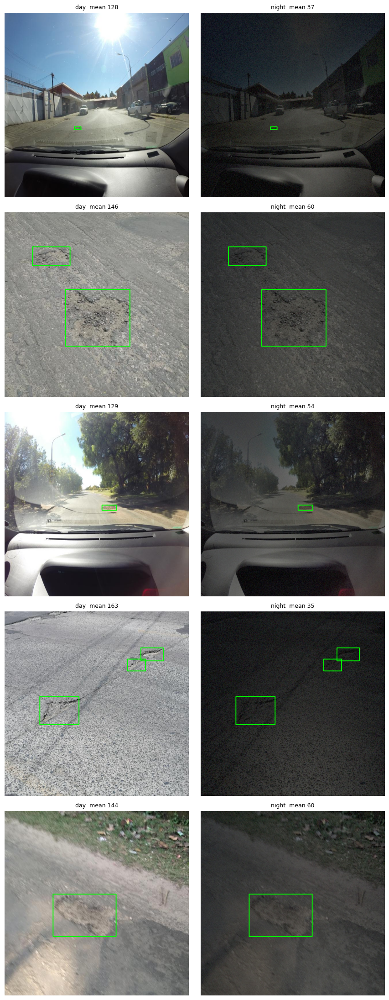

Average brightness over 150 train images:  day 131   night 53   (0-255 scale)


In [ ]:
# Cell 3 - spot-check: 5 random train images, day vs night, with the pothole boxes drawn
import random

names = sorted(p.name for p in (DST / "train" / "images").glob("*"))
random.seed(7)
pick = random.sample(names, min(5, len(names)))

fig, axes = plt.subplots(len(pick), 2, figsize=(9, 4.4 * len(pick)), squeeze=False)
for r, name in enumerate(pick):
    for c, (tag, folder) in enumerate([("day", SRC), ("night", DST)]):
        im = read_image(folder / "train" / "images" / name)
        m = mean_luma(im)
        h, w = im.shape[:2]
        for x0, y0, x1, y1 in read_boxes(folder / "train" / "labels" / (Path(name).stem + ".txt"), w, h):
            cv2.rectangle(im, (x0, y0), (x1, y1), (0, 255, 0), 2)
        axes[r][c].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        axes[r][c].set_title(f"{tag}  mean {m:.0f}", fontsize=9)
        axes[r][c].axis("off")
plt.tight_layout()
plt.show()

sample = random.sample(names, min(150, len(names)))
day_avg = np.mean([mean_luma(read_image(SRC / "train" / "images" / n)) for n in sample])
night_avg = np.mean([mean_luma(read_image(DST / "train" / "images" / n)) for n in sample])
print(f"Average brightness over {len(sample)} train images:  day {day_avg:.0f}   night {night_avg:.0f}   (0-255 scale)")

In [ ]:
import os, shutil
from google.colab import files

zip_path = shutil.make_archive("/content/night_synthetic", "zip", "/content", "night_synthetic")
print(f"{zip_path}  ({os.path.getsize(zip_path) / 1e6:.0f} MB)")
files.download(zip_path)

/content/night_synthetic.zip  (516 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from google.colab import files

# Compress the entire dataset folder
shutil.make_archive(
    '/content/night_synthetic',
    'zip',
    '/content',
    'night_synthetic'
)

# Download the ZIP to your PC
files.download('/content/night_synthetic.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>